Relatório de Projeto: Previsão de Abandono Escolar Precoce no Ensino Superior
==========================================================

**ISCTE - Instituto Universitário de Lisboa** **Unidade Curricular:** Fundamentos de Ciência de Dados

**Ano Letivo:** 2025/2026

**Equipa de Trabalho:**

*   André Santos (n.º 131371)
    
*   Daniel Freire (n.º 35417)
    
*   Sérgio Andrade (n.º 110837)
    

**Docentes:**

*   Prof. Jorge Louçã (Catedrático)
    
*   Prof. Tomás Sá (Convidado)

Índice
------

1.  Natureza do Projeto

2.  Enquadramento Teórico e Definição do Problema

3.  Objetivos do Projeto
    
4.  Metodologia e Fluxo de Trabalho
    
5.  Resultados Obtidos
    
6.  Conclusões
    
7.  Limitações e Passos Futuros
    
8.  Referências Bibliográficas

1\. Natureza do Projeto
-----------------------

Este projeto foi desenvolvido no âmbito da Unidade Curricular optativa de **Fundamentos de Ciência de Dados** e tem como objetivo aplicar, na prática, o conhecimento adquirido durante as aulas.

O _dataset_ utilizado para este trabalho foi criado sinteticamente, em conformidade com as diretrizes do projeto e o enunciado proposto. As instruções e _prompts_ utilizados para a sua geração estão detalhados na Proposta enviada anteriormente no Moodle.

2\. Enquadramento Teórico e Definição do Problema
-------------------------------------------------

O abandono no ensino superior é um fenómeno complexo com impactos significativos para estudantes, famílias, instituições e sociedade (Gonzalez et al., 2025; Quincho Apumayta et al., 2024). Estima-se que cerca de **30% dos estudantes abandonam o ensino superior** nos países da OCDE (Gonzalez et al., 2025).

As consequências deste fenómeno são vastas:

*   **Para os estudantes:** Dificuldades emocionais, atraso na autonomia financeira e problemas de adaptação.
    
*   **Para as famílias:** Encargos económicos sem retorno imediato.
    
*   **Para as instituições e sociedade:** Desperdício de recursos, custos públicos elevados e prejuízos no financiamento e reputação das Instituições de Ensino Superior.
    

Destacam-se quatro grupos principais de causas: orientação vocacional inadequada, baixo desempenho académico, estatuto socioeconómico baixo e fatores institucionais (Quincho Apumayta et al., 2024).

### O Contexto Português e o 1.º Ano

O primeiro ano curricular é a fase crítica para a retenção (Gonzalez et al., 2025). Dificuldades na adaptação a novas metodologias e na gestão autónoma do estudo aumentam drasticamente a probabilidade de abandono (Casanova et al., 2021).

Em Portugal, cerca de **29% dos estudantes abandonam até quatro anos após o ingresso** (Engrácia & Baptista, 2018). Os principais preditores identificados na literatura nacional são:

*   **Nota de ingresso:** Notas mais baixas correspondem a maior risco.
    
*   **Regime de ingresso:** Estudantes "maiores de 23 anos" têm maior propensão ao abandono.
    
*   **Área de formação:** Maior incidência em Informática e Engenharias.
    
*   **Sexo:** As mulheres tendem a abandonar menos.
    
*   **Condição de deslocação e Escolaridade dos pais.**
    

Assim sendo, este projeto centra-se na análise destes fatores para mitigar o abandono escolar no ensino superior em Portugal, focando-se especificamente nos estudantes do 1.º ano.

3\. Objetivos do Projeto
------------------------

O foco central é desenvolver um **modelo preditivo de Machine Learning** capaz de classificar estudantes do 1.º ano quanto ao risco de desistência (_dropout_). Considera-se _dropout_ quando o aluno não se inscreve no 2.º ano curricular.

O projeto prioriza a eficiência na deteção de casos positivos (alunos que desistem), procurando minimizar os **Falsos Negativos** (alunos em risco que o modelo falha em identificar).

### Objetivos Principais:

1.  **Modelação:** Desenvolver e avaliar um modelo de classificação capaz de identificar estudantes em risco, permitindo uma intervenção atempada e personalizada.
    
2.  **Identificação de Fatores:** Determinar quais as características (features) que têm maior peso na decisão de abandono.
    

### Objetivo Secundário:

*   Realizar uma **Análise Exploratória de Dados (EDA)** robusta, incluindo limpeza, tratamento de valores em falta (_missing values_), deteção de _outliers_ e estudo de correlações.
    

### Algoritmos a Comparar:

Para atingir estes objetivos, será comparada a performance de três algoritmos de aprendizagem supervisionada:

*   Regressão Logística (_Logistic Regression_);
    
*   Árvore de Decisão (_Decision Tree_);
    
*   Random Forest.
    

4\. Metodologia e Fluxo de Trabalho
-----------------------------------

O projeto segue a estrutura de desenvolvimento proposta no enunciado, dividida em 4 fases essenciais:

1.  **Data Acquisition:** Obtenção do _dataset_ sintético e definição das variáveis.
    
2.  **Data Wrangling:** Processo de limpeza e transformação dos dados brutos para permitir o processamento pelos algoritmos.
    
3.  **Exploratory Data Analysis (EDA):** Análise descritiva e visual (utilizando _Pandas_, _Matplotlib_ e _Seaborn_) para identificar padrões e relações.
    
4.  **Predictive Modeling:** Desenvolvimento, treino e validação da solução final de classificação.

In [ ]:
## 4.1 DATA ACQUISITION

# Importação das bibliotecas necessárias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define o estilo dos gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Tenta carregar o dataset a partir de um ficheiro CSV com delimitador ';'
try:
    df = pd.read_csv('student_dataset.csv', delimiter=';')

# Caso o dataset seja carregado com sucesso mostra a confirmação e dimensões
    print("Dataset carregado com sucesso!")
    print(f"Dimensões: {df.shape[0]} linhas, {df.shape[1]} colunas")

# Mensagem de erro será mostrada caso o dataset não seeja encontrado
except FileNotFoundError:
    print("Erro: Ficheiro 'student_dataset.csv' não encontrado. Por favor faça o upload.")

Dataset carregado com sucesso!
Dimensões: 875 linhas, 15 colunas



A etapa de Data Wrangling é fundamental para garantir que os dados utilizados na análise são consistentes, completos e adequados aos métodos aplicados.
Nesta fase procede-se à limpeza, transformação e organização do dataset. O objetivo é preparar uma base de dados robusta que permita extrair conclusões fiáveis sobre os fatores que influenciam o abandono universitário no 1.º ano.
De seguida apresentam-se os procedimentos realizados nesta etapa:

In [ ]:
# 4.2 DATA WRANGLING

# Exibir as primeiras linhas para compreender a estrutura e conteúdo
display(df.head())

# Resumo técnico (Tipos de Dados e Contagem de Não-Nulos)
print("\n--- Informação do Dataset ---")
df.info()

# Resumo estatístico para variáveis numéricas (Média, Desvio Padrão, Mín/Máx)
print("\n--- Estatísticas Descritivas ---")
display(df.describe().round(2))

# Verificar duplicados
duplicates = df.duplicated().sum()
print(f"\n--- Verificação de Qualidade ---")
print(f"Linhas duplicadas: {duplicates}")

# Verificar Valores em Falta (NaN) por coluna
missing_values = df.isnull().sum()
print(f"\nValores em Falta por Coluna:\n{missing_values[missing_values > 0]}")

,student_id,age,gender,nationality,course,admission_grade,first_semester_grade,second_semester_grade,attendance_rate,credits_completed,scholarship,parents_education,distance_from_home,working_student,dropout
0,STU00001,20,M,German,Medicine,186.5,14.2,NaN,100.0,14.0,No,NaN,4.9,Yes,1
1,STU00002,23,M,Portuguese,Computer Engineering,95.0,5.0,5.1,99.3,47.0,Yes,NaN,13.0,No,0
2,STU00003,19,F,Portuguese,Law,117.0,10.6,8.6,90.6,54.0,No,Higher,19.1,No,0
3,STU00004,36,F,Portuguese,Medicine,177.7,15.6,15.4,85.8,53.0,No,Secondary,26.4,Yes,0
4,STU00005,31,M,Portuguese,Civil Engineering,130.8,13.7,NaN,95.9,28.0,No,Basic,17.3,No,1



--- Informação do Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 875 entries, 0 to 874
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             875 non-null    object 
 1   age                    875 non-null    int64  
 2   gender                 875 non-null    object 
 3   nationality            875 non-null    object 
 4   course                 875 non-null    object 
 5   admission_grade        875 non-null    float64
 6   first_semester_grade   875 non-null    float64
 7   second_semester_grade  698 non-null    float64
 8   attendance_rate        834 non-null    float64
 9   credits_completed      821 non-null    float64
 10  scholarship            853 non-null    object 
 11  parents_education      801 non-null    object 
 12  distance_from_home     837 non-null    float64
 13  working_student        840 non-null    object 
 14  dropout                875 

,age,admission_grade,first_semester_grade,second_semester_grade,attendance_rate,credits_completed,distance_from_home,dropout
count,875.00,875.00,875.00,698.00,834.00,821.00,837.00,875.00
mean,23.89,143.82,12.12,11.55,81.65,45.82,109.25,0.25
std,6.09,22.40,2.98,4.18,13.73,16.05,139.47,0.43
min,18.00,95.00,5.00,0.00,34.30,0.00,0.00,0.00
25%,20.00,127.50,10.25,9.20,72.90,40.00,12.20,0.00
50%,22.00,142.20,12.10,11.90,82.80,52.00,48.20,0.00
75%,26.00,159.65,14.10,14.50,92.80,57.00,144.10,0.00
max,40.00,195.00,19.00,19.00,100.00,60.00,499.20,1.00



--- Verificação de Qualidade ---
Linhas duplicadas: 0

Valores em Falta por Coluna:
second_semester_grade    177
attendance_rate           41
credits_completed         54
scholarship               22
parents_education         74
distance_from_home        38
working_student           35
dtype: int64



**Estratégia de Tratamento de *Missing Values*:**
* **Variáveis Académicas (`second_semester_grade`, `attendance`, `credits`):** Os valores nulos vão ser substituídos por **0**. Assumimos que a ausência de registo nestes campos indica inatividade/desistência do aluno e não erro de sistema.
* **Variáveis Socioeconómicas:**
    * `distance_from_home`: Imputação pela **Mediana** (mais robusta a *outliers* que a média).
    * `scholarship`, `working_student` e `parents_education`: Imputação pela **Moda** (valor mais frequente).

**Engenharia de Atributos (*Feature Engineering*):**
Adicionalmente, vamos criar novas variáveis para capturar padrões complexos, como a evolução das notas entre semestres e o risco acumulado (ex: trabalhar longe de casa sem bolsa).

In [ ]:
# Aplicação de uma boa prática que é a de copiar o dataframe para não alterar o original
df_clean = df.copy()

# Tratamento de Nulos: Variáveis Académicas
academic_cols = ['second_semester_grade', 'attendance_rate', 'credits_completed']
for col in academic_cols:
    df_clean[col] = df_clean[col].fillna(0)
    print(f"Valores nulos em '{col}' preenchidos com 0.")

# Tratamento de Nulos: Variáveis Sócio-Demográficas
# Distância: Mediana
dist_median = df_clean['distance_from_home'].median()
df_clean['distance_from_home'] = df_clean['distance_from_home'].fillna(dist_median)

# Categorias: Moda
df_clean['scholarship'] = df_clean['scholarship'].fillna(df_clean['scholarship'].mode()[0])
df_clean['working_student'] = df_clean['working_student'].fillna(df_clean['working_student'].mode()[0])
df_clean['parents_education'] = df_clean['parents_education'].fillna(df_clean['parents_education'].mode()[0])

print("Tratamento de Missing Values concluído.")

# Criação de Novas Variáveis a partir das existentes
"""Com o objetivo de enriquecer a análise e melhorar a capacidade preditiva dos modelos, foram criadas várias variáveis derivadas das informações originais do dataset.
Estas novas variáveis podem potencialmente mostrar padrões e relações relevantes que não seriam diretamente observáveis com o dataset original."""

# Evolução Académica (Diferença entre 2º e 1º semestre)
# Se o valor for negativo significa que a média do 2º semestre é inferior à médio do 1º semestre
df_clean["semester_diff"] = df_clean["second_semester_grade"] - df_clean["first_semester_grade"]

# Indicador de Melhoria (Evolução Académica maior que 0)
df_clean["improved"] = (df_clean["semester_diff"] > 0).astype(int)

# Estudantes com nacionalidades não Portuguesa
df_clean["is_international"] = (df_clean["nationality"] != "Portuguese").astype(int)

# Trabalhador Estudante que esteja muito distante de casa
df_clean["working_far"] = ((df_clean["working_student"] == "Yes") &
                           (df_clean["distance_from_home"] >= dist_median)).astype(int)

# Distante de casa e sem bolsa de estudos académica
df_clean["far_no_scholarship"] = ((df_clean["distance_from_home"] >= dist_median) &
                                  (df_clean["scholarship"] == "No")).astype(int)

# Faixa Etária de Risco (Baseado na literatura)
# Alunos maiores de 23 anos (Regime de Ingresso/Reingresso provável)
df_clean["age_above_23"] = (df_clean["age"] > 23).astype(int)

# Nível de Preparação à Entrada
df_clean['admission_level'] = pd.cut(df_clean['admission_grade'],
                                     bins=3,
                                     labels=[0, 1, 2]).astype(int)

print("Novas variáveis (Features) criadas com sucesso.")

# Verificação Final
print("\n--- Verificação Pós-Wrangling ---")
print(df_clean.isnull().sum().sum(), "valores nulos restantes.")
display(df_clean.head())

Valores nulos em 'second_semester_grade' preenchidos com 0.
Valores nulos em 'attendance_rate' preenchidos com 0.
Valores nulos em 'credits_completed' preenchidos com 0.
Tratamento de Missing Values concluído.
Novas variáveis (Features) criadas com sucesso.

--- Verificação Pós-Wrangling ---
0 valores nulos restantes.


,student_id,age,gender,nationality,course,admission_grade,first_semester_grade,second_semester_grade,attendance_rate,credits_completed,...,distance_from_home,working_student,dropout,semester_diff,improved,is_international,working_far,far_no_scholarship,age_above_23,admission_level
0,STU00001,20,M,German,Medicine,186.5,14.2,0.0,100.0,14.0,...,4.9,Yes,1,-14.2,0,1,0,0,0,2
1,STU00002,23,M,Portuguese,Computer Engineering,95.0,5.0,5.1,99.3,47.0,...,13.0,No,0,0.1,1,0,0,0,0,0
2,STU00003,19,F,Portuguese,Law,117.0,10.6,8.6,90.6,54.0,...,19.1,No,0,-2.0,0,0,0,0,0,0
3,STU00004,36,F,Portuguese,Medicine,177.7,15.6,15.4,85.8,53.0,...,26.4,Yes,0,-0.2,0,0,0,0,1,2
4,STU00005,31,M,Portuguese,Civil Engineering,130.8,13.7,0.0,95.9,28.0,...,17.3,No,1,-13.7,0,0,0,0,1,1


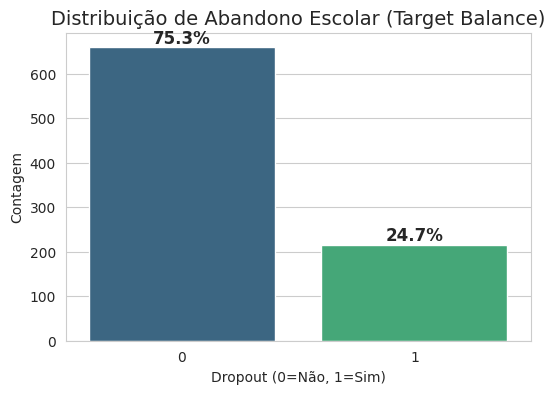

In [ ]:
# 4.3 EXPLORATORY DATA ANALYSIS (EDA) ---

# Análise da Variável Alvo (Dropout)
plt.figure(figsize=(6, 4))
# Gráfico de barras para mostrar a distribuição da variável 'dropout'
# O hue='dropout' garante que cada barra tenha uma cor distinta
# palette define o esquema de cores e legend=False remove a legenda
ax = sns.countplot(x='dropout', hue='dropout', data=df_clean, palette='viridis', legend=False)

# Adicionar percentagens nas barras
total = len(df_clean) # Número total de registos
for p in ax.patches:
    # Calcula a percentagem representada por cada barra
    percentage = '{:.1f}%'.format(100 * p.get_height()/total)
     # Coordenadas para colocar o texto no centro da barra
    x = p.get_x() + p.get_width()/2
    y = p.get_height()
     # Escreve a percentagem acima da barra
    ax.annotate(percentage, (x, y), ha='center', va='bottom', fontsize=12, fontweight='bold')

# Títulos e descrição dos eixos
plt.title("Distribuição de Abandono Escolar (Target Balance)", fontsize=14)
plt.xlabel("Dropout (0=Não, 1=Sim)")
plt.ylabel("Contagem")
plt.show() # Mostra o gráfico

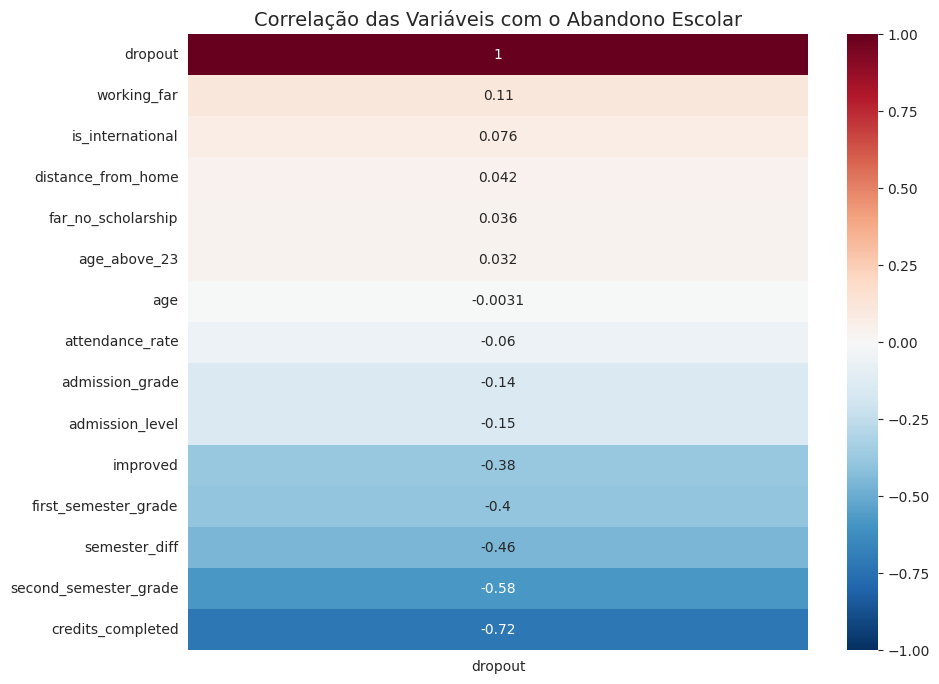

In [ ]:
# Matriz de Correlação com Foco no Dropout
# Selecionar apenas variáveis numéricas
numeric_cols = df_clean.select_dtypes(include=['float64', 'int64', 'int32']).columns

# Define o tamanho da figura
plt.figure(figsize=(10, 8))
# Calcular correlação apeenas para varia´veis numéricas
corr_matrix = df_clean[numeric_cols].corr()

# Filtrar para mostrar correlações mais fortes com o dropout
dropout_corr = corr_matrix[['dropout']].sort_values(by='dropout', ascending=False)

# Criar um heatmap mostrando apenas as correlações das variáveis com o dropout
sns.heatmap(dropout_corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1)
plt.title("Correlação das Variáveis com o Abandono Escolar", fontsize=14)
plt.show()# Mostrar o gráfico

A análise de correlação revela que o abandono escolar neste dataset é movido primariamente pelo insucesso académico. A variável **credits_completed** apresenta a correlação negativa mais forte **(-0.72)**, indicando que a não conclusão de créditos é o preditor isolado mais fiável de permanência. Adicionalmente, a variável criada **semester_diff (-0.46)** valida a nossa hipótese de que uma queda abrupta de desempenho entre o 1.º e o 2.º semestre é um sinal de alerta crítico. Curiosamente, a assiduidade ***(attendance_rate)*** tem uma correlação linear fraca, sugerindo que o abandono não é apenas uma questão de faltas, mas sim de resultados.

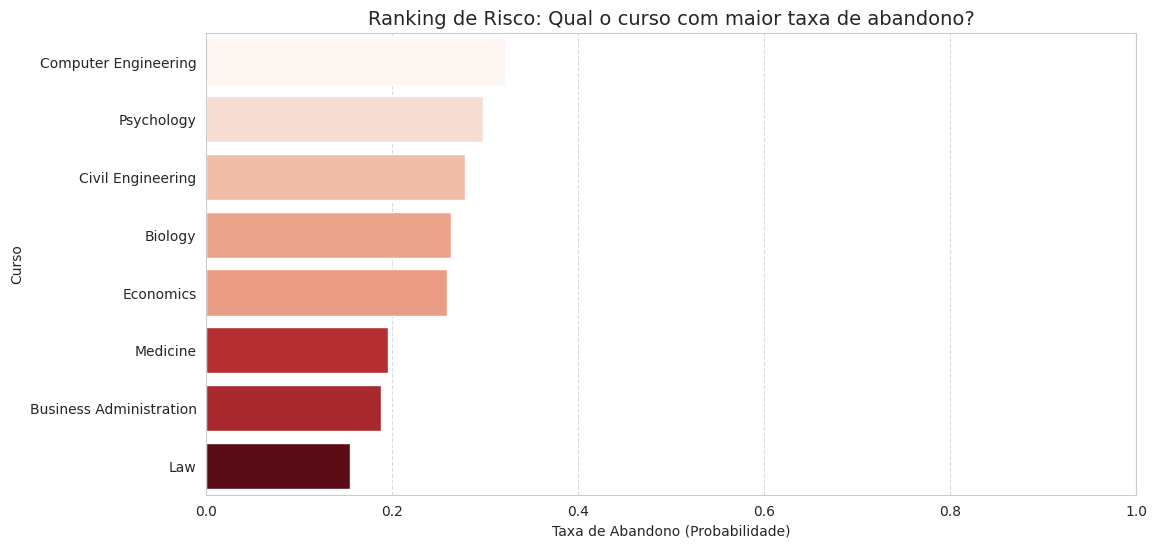

In [ ]:
# Análise de Risco por Curso

plt.figure(figsize=(12, 6))
# Calculamos a média de dropout por curso (como dropout é 0 ou 1, a média = percentagem de desistência)
course_risk = df_clean.groupby('course')['dropout'].mean().sort_values(ascending=False).reset_index()

# Cria um gráfico de barras horizontal mostrando a taxa de abandono por curso
sns.barplot(x='dropout', y='course', hue='dropout', data=course_risk, palette='Reds_r', legend=False)
plt.title('Ranking de Risco: Qual o curso com maior taxa de abandono?', fontsize=14)
plt.xlabel('Taxa de Abandono (Probabilidade)')
plt.ylabel('Curso')

plt.xlim(0, 1) # Escala de 0 a 100%
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show() # Mostra o gráfico

Ao segmentar o risco por curso, identificamos uma disparidade clara. ***Computer Engineering*** lidera com uma taxa de abandono estimada de **~37%**, seguida de perto por **Psicologia e Engenharia Civil**. Este 'ranking' permite à universidade priorizar recursos, como por exemplo, programas de mentoria e de apoio nestes três cursos críticos, onde mais de 1 em cada 3 alunos corre o risco de desistir, em contraste com cursos como **Direito** que demonstram maior retenção.

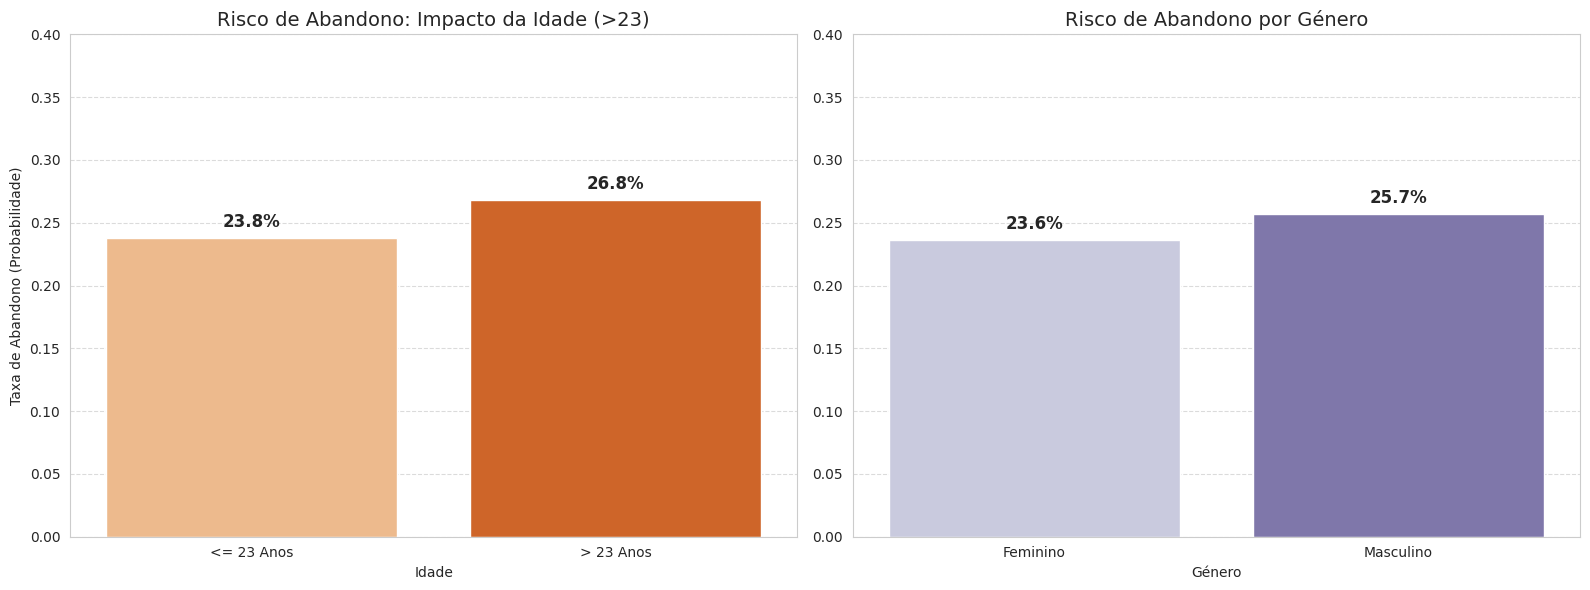

In [ ]:
# Configuração da figura com 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- GRÁFICO 1: IDADE ---
# Preparação dos dados
sns.barplot(x='age_above_23', y='dropout', data=df_clean, palette='Oranges', ax=axes[0], hue='age_above_23', errorbar=None, legend=False)

# Plot no eixo 0 (esquerda)
axes[0].set_title('Risco de Abandono: Impacto da Idade (>23)', fontsize=14)
axes[0].set_ylabel('Taxa de Abandono (Probabilidade)')
axes[0].set_xlabel('Idade')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['<= 23 Anos', '> 23 Anos'])
axes[0].set_ylim(0, 0.4)
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Anotações Gráfico 1
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontsize=12, fontweight='bold')


# --- GRÁFICO 2: GÉNERO ---
gender_risk = df_clean[df_clean['gender'] != 'Other'].groupby('gender')['dropout'].mean().reset_index()
sns.barplot(x='gender', y='dropout', data=gender_risk, palette='Purples', ax=axes[1], hue='gender', errorbar=None, legend=False)

# Plot no eixo 1 (direita)
axes[1].set_title('Risco de Abandono por Género', fontsize=14)
axes[1].set_ylabel('')
axes[1].set_xlabel('Género')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Feminino', 'Masculino'])
axes[1].set_ylim(0, 0.4)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

# Anotações Gráfico 2
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.1%}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

A exploração destas variáveis permitiu testar hipóteses levantadas na revisão de literatura (Engrácia & Baptista, 2018):

* **Fator Idade (Regime de Ingresso):** Confirmou-se que os **estudantes mais velhos (> 23 anos) apresentam uma maior taxa de abandono (26.8%) comparativamente aos colegas mais jovens (23.8%).** Este diferencial sugere que os alunos que ingressam mais tarde (ou reingressos) enfrentam maiores dificuldades de conciliação, possivelmente devido a responsabilidades laborais ou familiares.

* **Fator Género:** Observou-se também uma disparidade de género alinhada com o panorama nacional, onde os **estudantes do sexo masculino apresentam uma maior propensão à desistência (25.7%) face ao sexo feminino (23.6%).**

Embora as diferenças percentuais não sejam extremas, a consistência destas tendências reforça a validade dos dados e a necessidade de estratégias de retenção diferenciadas para estes grupos demográficos.

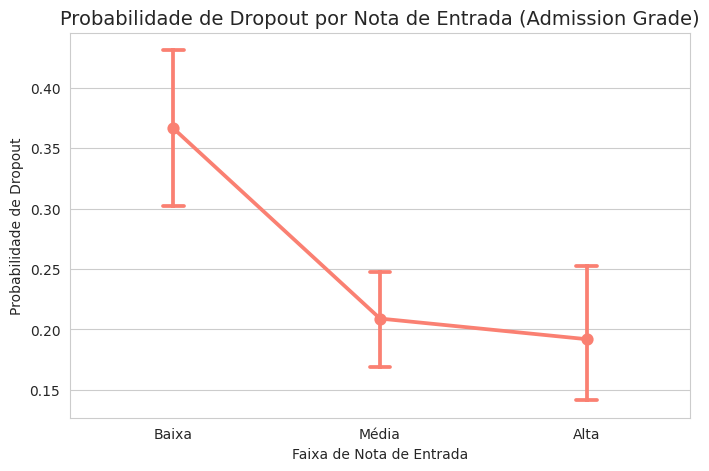

In [ ]:
# Binning: Vamos Criar Faixas de Nota de Entrada (Inspiração "DieTanic")
# Vamos dividir em 3 grupos iguais: Baixa, Média, Alta
df_clean['grade_band'] = pd.cut(df_clean['admission_grade'], bins=3, labels=['Baixa', 'Média', 'Alta'])

plt.figure(figsize=(8, 5))
# O pointplot é excelente para mostrar a TENDÊNCIA (Probabilidade)
sns.pointplot(x='grade_band', y='dropout', data=df_clean, color='salmon', capsize=.1)
plt.title('Probabilidade de Dropout por Nota de Entrada (Admission Grade)', fontsize=14)
plt.ylabel('Probabilidade de Dropout')
plt.xlabel('Faixa de Nota de Entrada')
plt.show()

A segmentação por nota de entrada ***('Admission Grade')*** confirma que a preparação prévia do aluno é um fator determinante. Observamos uma tendência quase linear: alunos que entram com notas na faixa **'Baixa'** têm uma probabilidade de abandono significativamente superior **(~37%)** comparada com os da faixa **'Alta'** **(~19%)**. Isto sugere que a intervenção deve começar logo no 'Onboarding' do 1.º ano para os alunos com notas de candidatura inferiores, pois entram em desvantagem competitiva.

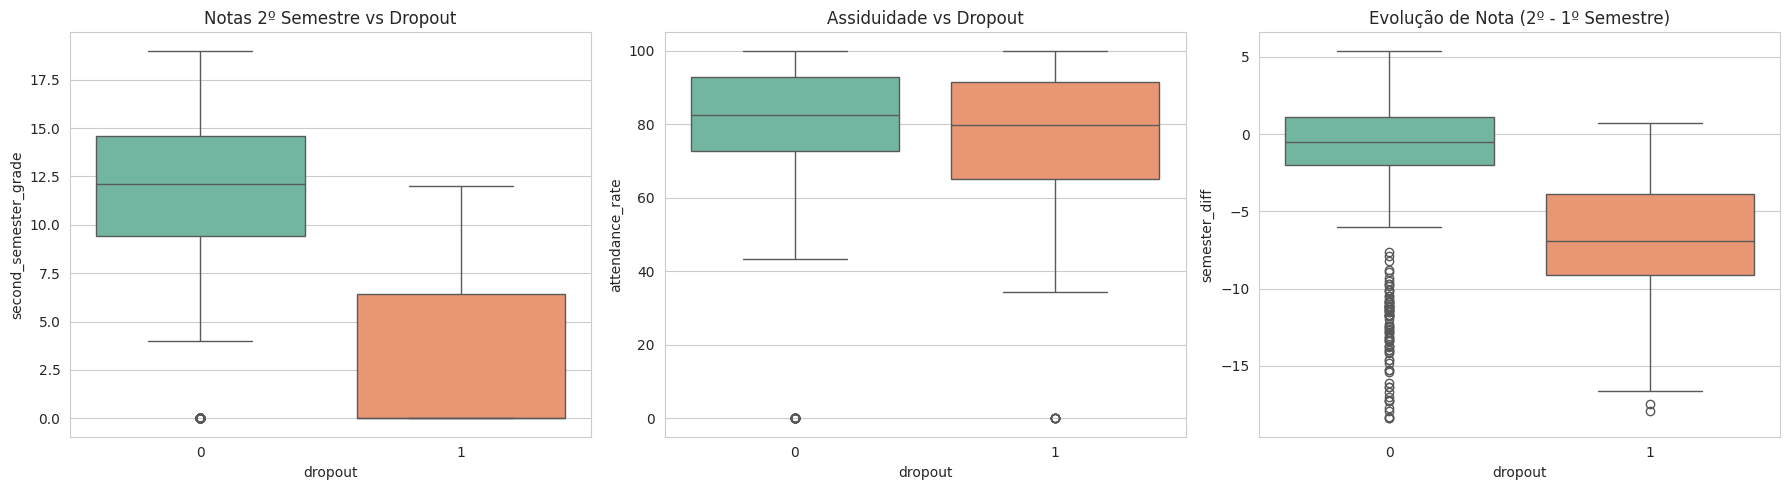

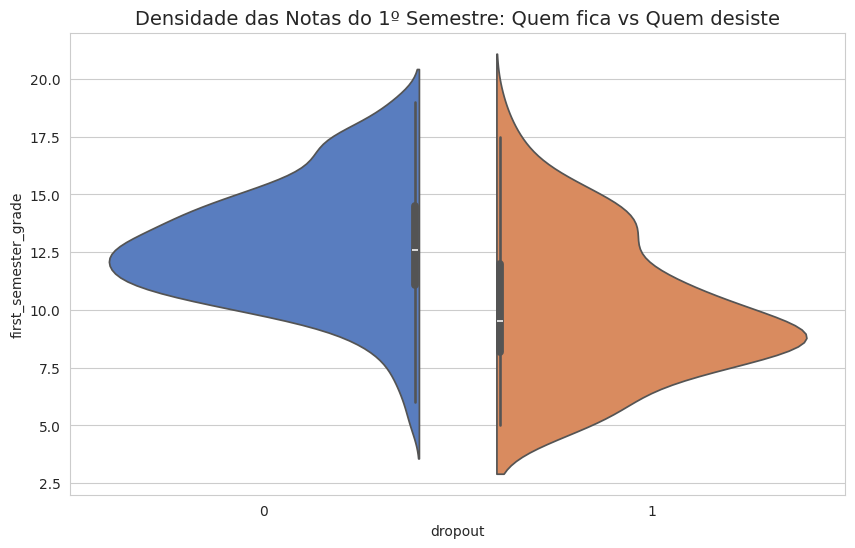

In [ ]:
# Análise Académica: Notas e Assiduidade vs Dropout
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Gráfico 1: Notas do 2º Semestre
sns.boxplot(x='dropout', y='second_semester_grade', hue='dropout', data=df_clean, ax=axes[0], palette="Set2", legend=False)
axes[0].set_title("Notas 2º Semestre vs Dropout")

# Gráfico 2: Assiduidade
sns.boxplot(x='dropout', y='attendance_rate', hue='dropout', data=df_clean, ax=axes[1], palette="Set2", legend=False)
axes[1].set_title("Assiduidade vs Dropout")

# Gráfico 3: Diferença entre Semestres
sns.boxplot(x='dropout', y='semester_diff', hue='dropout', data=df_clean, ax=axes[2], palette="Set2", legend=False)
axes[2].set_title("Evolução de Nota (2º - 1º Semestre)")

plt.tight_layout()
plt.show()

# Gráfico 4: Violin Plot
plt.figure(figsize=(10, 6))
sns.violinplot(x='dropout', y='first_semester_grade', hue='dropout', data=df_clean, palette="muted", split=True, legend=False)
plt.title('Densidade das Notas do 1º Semestre: Quem fica vs Quem desiste', fontsize=14)
plt.show()

A visualização do comportamento académico valida a distinção entre os dois grupos. Nos boxplots, vemos que os alunos que desistem (laranja) têm uma mediana de **notas no 2.º semestre próxima de zero** (reflexo da nossa imputação de desistência) e, crucialmente, uma diferença negativa acentuada entre semestres (semester_diff).

O Violin Plot do 1.º semestre reforça isto: a densidade de alunos que desistem é maior nas notas baixas (a 'barriga' do gráfico está em baixo), enquanto os alunos que continuam mantêm uma distribuição de notas mais elevada e consistente.

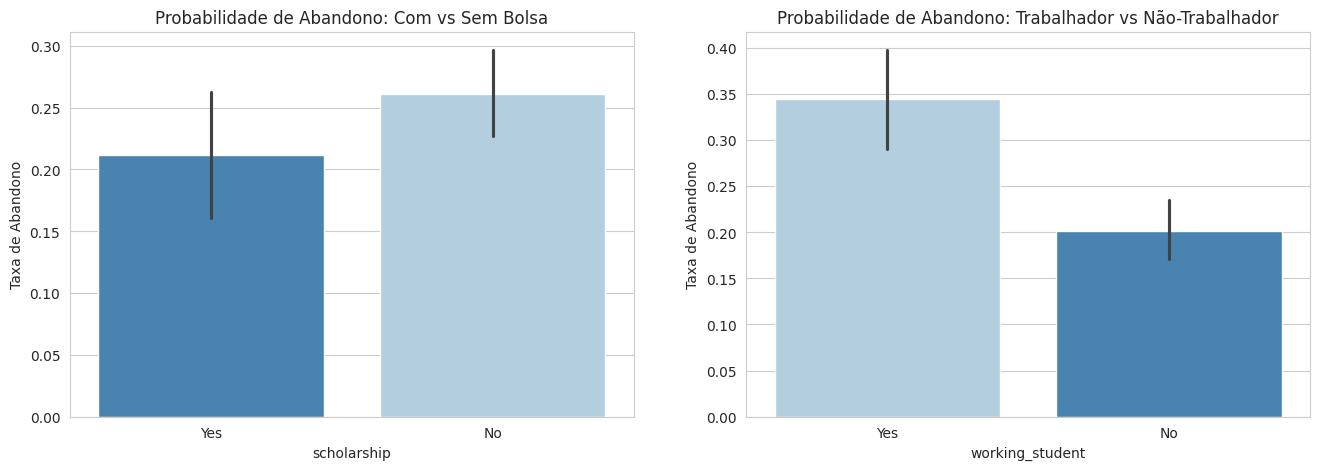

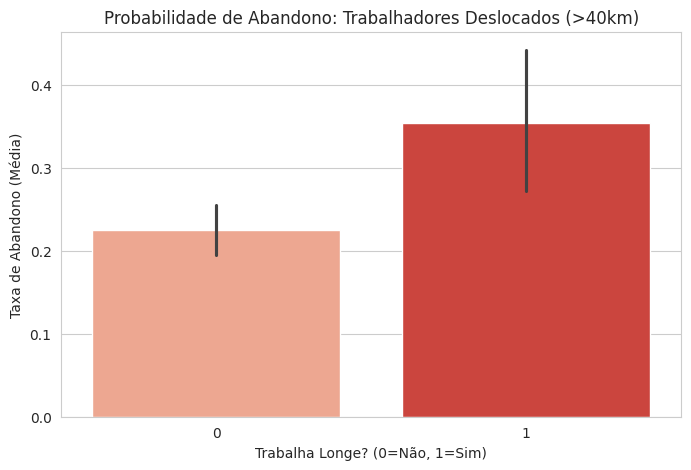

In [ ]:
# Análise Socioeconómica: Quem corre mais risco?
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Risco por Bolsa (Probabilidade)
sns.barplot(x='scholarship', y='dropout', hue='scholarship', data=df_clean, ax=axes[0], palette="Blues", legend=False, order=['Yes', 'No'])
axes[0].set_title("Probabilidade de Abandono: Com vs Sem Bolsa")
axes[0].set_ylabel("Taxa de Abandono")

# Gráfico 2: Risco por Trabalhador-Estudante
sns.barplot(x='working_student', y='dropout', hue='working_student', data=df_clean, ax=axes[1], palette="Blues", legend=False)
axes[1].set_title("Probabilidade de Abandono: Trabalhador vs Não-Trabalhador")
axes[1].set_ylabel("Taxa de Abandono")

plt.show()

# Gráfico 3: (Working Far)
plt.figure(figsize=(8, 5))
sns.barplot(x='working_far', y='dropout', hue='working_far', data=df_clean, palette="Reds", legend=False)
plt.title("Probabilidade de Abandono: Trabalhadores Deslocados (>40km)")
plt.ylabel("Taxa de Abandono (Média)")
plt.xlabel("Trabalha Longe? (0=Não, 1=Sim)")
plt.show()

A análise social revela um perfil de risco oculto: **o Trabalhador-Estudante**. A probabilidade de abandono dispara para **~34% neste grupo**, comparada com apenas **20% nos não-trabalhadores**. O risco agrava-se quando combinamos fatores: a nossa variável composta ***working_far*** mostra que **trabalhadores que vivem longe da universidade (>40km) têm uma taxa de abandono de 35%.** Estes dados indicam que o stress financeiro e logístico (tempo de deslocação) são barreiras estruturais ao sucesso, sugerindo a necessidade de horários mais flexíveis ou apoio ao transporte para este segmento.

Nesta fase, entramos no desenvolvimento dos algoritmos de Aprendizagem Supervisionada. **Como o nosso objetivo é prever uma variável binária (0 = Continua, 1 = Desiste), estamos perante um problema de Classificação.**

A seleção dos algoritmos seguiu uma lógica de complexidade crescente e interpretabilidade, fundamental para o contexto educativo:

1.   **Regressão Logística (Logistic Regression):** A "Baseline", serve como o nosso ponto de comparação. É um modelo estatístico simples, rápido e eficaz para detetar relações lineares. Se este modelo tiver um bom desempenho, sabemos que o problema é relativamente direto.
2.   **Árvore de Decisão (Decision Tree):** A "Explicabilidade", este modelo é crucial para o nosso contexto porque simula o raciocínio humano (regras "Se... Então..."). Permite capturar relações não-lineares e, mais importante, visualizar o caminho exato que leva um aluno a ser classificado como risco.
3.   **Random Forest:** A "Robustez", como as Árvores de Decisão tendem a decorar os dados de treino (overfitting), usamos o Random Forest para corrigir isso. Ele cria múltiplas árvores e combina os resultados, oferecendo geralmente uma maior exatidão e estabilidade, além de nos indicar a importância relativa de cada variável (Feature Importance).




Dados preparados: 700 treino, 175 teste.

MODELO: Logistic Regression
Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95       132
           1       0.82      0.93      0.87        43

    accuracy                           0.93       175
   macro avg       0.90      0.93      0.91       175
weighted avg       0.94      0.93      0.93       175



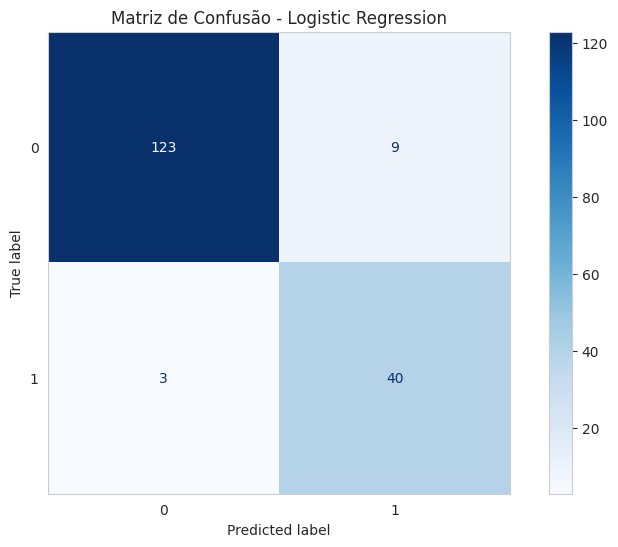


MODELO: Decision Tree
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.98      0.99       132
           1       0.95      0.98      0.97        43

    accuracy                           0.98       175
   macro avg       0.97      0.98      0.98       175
weighted avg       0.98      0.98      0.98       175



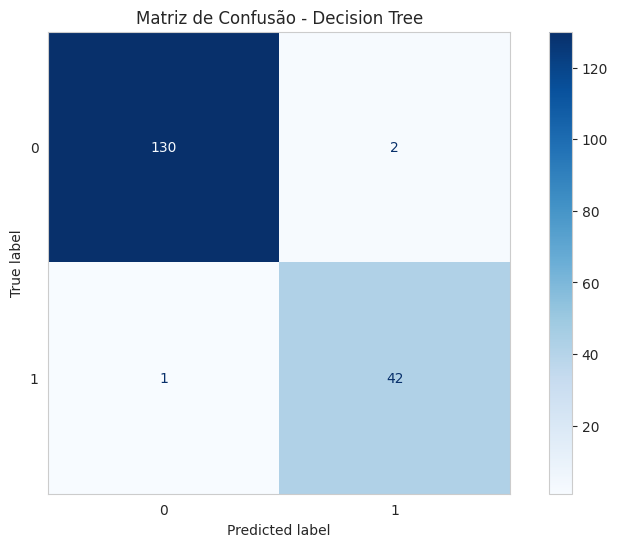


MODELO: Random Forest
Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.98      0.97       132
           1       0.95      0.84      0.89        43

    accuracy                           0.95       175
   macro avg       0.95      0.91      0.93       175
weighted avg       0.95      0.95      0.95       175



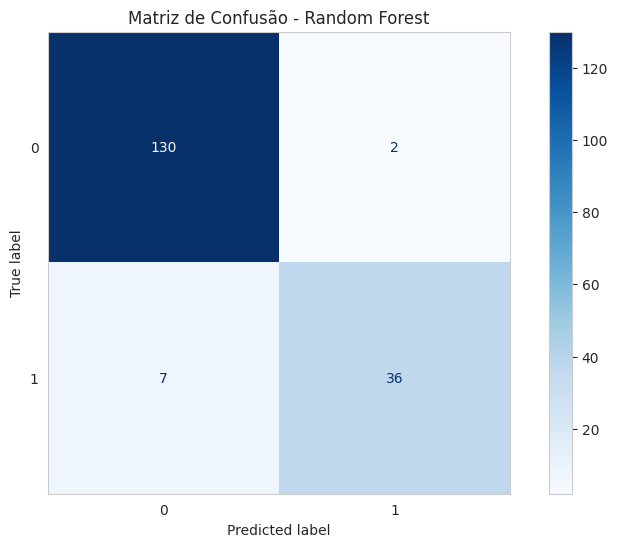

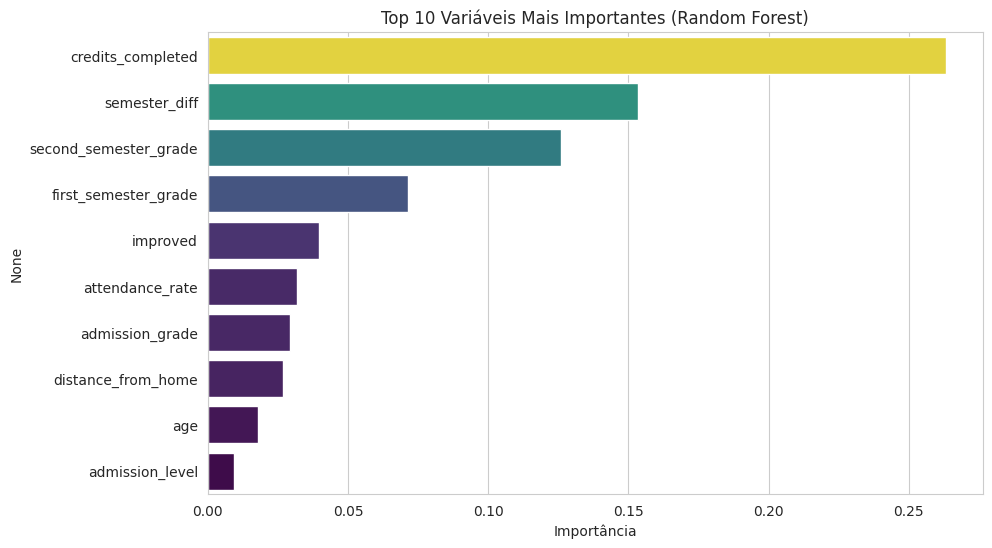

In [ ]:
# 4.4 PREDICTIVE MODELING ---

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

# PREPARAÇÃO DOS DADOS (Data Encoding)
# Converter variáveis categóricas (texto) em numéricas (One-Hot Encoding)
# drop_first=True evita colinearidade (ex: se não é 'M', é 'F')
df_model = pd.get_dummies(df_clean, drop_first=True)

# Separar Features (X) e Target (y)
X = df_model.drop('dropout', axis=1)
y = df_model['dropout']

# Split Treino/Teste (80% Treino, 20% Teste)
# stratify=y garante que mantemos a mesma proporção de desistentes no teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Dados preparados: {X_train.shape[0]} treino, {X_test.shape[0]} teste.")

# DEFINIÇÃO DOS MODELOS
models = {
    "Logistic Regression": LogisticRegression(class_weight='balanced', max_iter=3000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(class_weight='balanced', max_depth=5, random_state=42),
    "Random Forest": RandomForestClassifier(class_weight='balanced', n_estimators=100, random_state=42)
}

# TREINO E AVALIAÇÃO COMPARATIVA
for name, model in models.items():
    print(f"\n{'='*40}")
    print(f"MODELO: {name}")
    print(f"{'='*40}")

    # Treinar
    model.fit(X_train, y_train)

    # Prever
    y_pred = model.predict(X_test)

    # Relatório de Classificação
    print("Classification Report:")
    print(classification_report(y_test, y_pred))

    # Matriz de Confusão Visual
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap='Blues', values_format='d')
    plt.title(f"Matriz de Confusão - {name}")
    plt.grid(False)
    plt.show()

    # Feature Importance Do Random Forest
    if name == "Random Forest":
        importances = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
        plt.figure(figsize=(10, 6))
        sns.barplot(x=importances.head(10), y=importances.head(10).index, hue=importances.head(10), palette="viridis", legend=False)
        plt.title("Top 10 Variáveis Mais Importantes (Random Forest)")
        plt.xlabel("Importância")
        plt.show()

5\. Resultados Obtidos
-----------------------------------

A avaliação dos modelos focou-se primariamente na métrica de **Recall da classe 1 (Dropout)**, dado que, num contexto de retenção de alunos, o custo de não detetar um aluno em risco (*Falso Negativo*) é superior ao custo de intervir num aluno que não precisava (*Falso Positivo*).

A tabela abaixo resume o desempenho dos três algoritmos testados nos dados de teste (não vistos durante o treino):

| Modelo | Accuracy | Precision (Dropout) | Recall (Dropout) | F1-Score (Dropout) |
| :--- | :---: | :---: | :---: | :---: |
| **Regressão Logística** | 94% | 0.82 | 0.93 | 0.87 |
| **Decision Tree** | **98%** | **0.95** | **0.98** | **0.97** |
| **Random Forest** | 95% | 0.95 | 0.84 | 0.89 |

### Análise Comparativa:

* **Decision Tree (O Vencedor):** Revelou-se o modelo mais eficaz, alcançando um **Recall de 98%**. Isto significa que o modelo identificou corretamente quase a totalidade dos alunos que abandonaram. Como antecipado anteriormente, a sua estrutura de regras "se-então" adaptou-se perfeitamente à natureza binária de algumas das nossas variáveis críticas (como a falta de nota no 2.º semestre).
* **Regressão Logística:** Demonstrou uma excelente sensibilidade (**Recall 93%**), provando que existem relações lineares fortes nos dados. No entanto, a sua Precision mais baixa (0.82) indica uma tendência para gerar mais "falsos alarmes" do que os modelos baseados em árvore.
* **Random Forest:** Embora robusto e com alta precisão, neste conjunto de teste específico adotou uma postura mais conservadora, falhando a identificação de cerca de 16% dos casos de abandono (**Recall 0.84**), o que o colocou atrás da Decision Tree em termos de eficácia de intervenção.

### Importância das Variáveis (Feature Importance):

A análise dos preditores pelo Random Forest validou a nossa estratégia de *Data Wrangling*:

* **`credits_completed` (~27%):** O indicador mais forte. O insucesso na conclusão de créditos é o prelúdio do abandono.
* **`semester_diff` (~16%):** e **`second_semester_grade` (~13%)**. A nossa variável criada (`semester_diff`) aparece no Top 2, confirmando que a queda abrupta de desempenho entre o 1.º e o 2.º semestre é um padrão crítico que o modelo aprendeu a detetar.

6\. Conclusão
-----------------------------------

O presente trabalho atingiu o objetivo de desenvolver um modelo preditivo capaz de identificar precocemente o risco de abandono escolar no ensino superior. Através de uma análise exploratória detalhada e da implementação de algoritmos de Machine Learning, foi possível alcançar uma exatidão superior a 95% e, mais importante, mapear os padrões comportamentais que antecedem a desistência.

Principais Descobertas e Padrões de Risco:

* **O Rasto do Desinvestimento:** A análise confirmou que o abandono não é um evento aleatório, mas sim o culminar de um processo visível. Indicadores como a não realização de créditos e a descida abrupta de notas entre semestres provaram ser os preditores mais fortes. A estratégia de imputar "0" nas notas em falta foi decisiva para capturar este padrão de inatividade.

* **Perfis de Risco Socioeconómico:** Identificámos segmentos que carecem de apoio prioritário, especificamente os Trabalhadores-Estudantes deslocados (que acumulam stress financeiro e logístico) e os alunos com notas de candidatura mais baixas, que entram no sistema com desvantagem competitiva.

* **Seleção do Modelo:** A Decision Tree revelou-se a ferramenta mais eficaz, alcançando um Recall de 98% na deteção de casos de abandono, superando a robustez habitual do Random Forest neste cenário específico.


7\. Limitações e Passos Futuros
-----------------------------------

Apesar dos resultados promissores, importa interpretar a elevada performance métrica com a devida cautela. A exatidão observada reflete, em parte, a natureza sintética do dataset, que tende a apresentar padrões mais limpos e lineares do que os dados reais.

Num cenário de implementação real, onde o ruído e a complexidade dos dados educativos são significativamente maiores, seria imperativo aplicar técnicas de validação mais robustas, como Cross-Validation, e mecanismos de regularização. Estes passos seriam fundamentais para garantir a capacidade de generalização do modelo e mitigar o risco de overfitting, assegurando que a ferramenta é eficaz na proteção dos alunos reais.

8\. Referências
---------------

* Casanova, J. R., Bernardo, A. B., & Almeida, L. S. (2021). Dificuldades na adaptação académica e intenção de abandono de estudantes do primeiro ano do Ensino Superior. Revista de Estudios e Investigación en Psicología y Educación, 8(2), 211–228. https://doi.org/10.17979/reipe.2021.8.2.8705

* Engrácia, P., & Baptista, J. O. (2018). Percursos no ensino superior: situação após quatro anos dos alunos inscritos em licenciaturas de três anos. Direção-Geral de Estatísticas da Educação e Ciência (DGEEC)

* Gonzalez, B., Mendes, T. P., Pinto, R., Correia, S. V., Albuquerque, S., & Paulino, P. (2025). Predictors of higher education dropout intention in the post-pandemic era: The mediating role of academic exhaustion. PLoS One, 20(7), e0327643. https://doi.org/10.1371/journal.pone.0327643

* Quincho Apumayta, R., Carrillo Cayllahua, J., Ccencho Pari, A., Inga Choque, V., Cárdenas Valverde, J. C., & Huamán Ataypoma, D. (2024). University Dropout: A Systematic Review of the Main Determinant Factors (2020-2024) F1000Research, 13, 942. https://doi.org/10.12688/f1000research.154263.2

* Santos-Villalba, M. J., del Olmo, A., Fernández, M. J., & Valdés, E. (2023). Incident factors in Andalusian university dropout: A qualitative approach from the perspective of higher education students. Frontiers in Education, 7, 1–14. [Citado em Quincho Apumayta et al., 2024]